05 — Extension générative : auto-encodeur variationnel (Partie 5, option B)

Un **VAE** (Kingma & Welling, 2013) est un auto-encodeur dont l'encodeur ne produit pas un point mais une **loi** $q(z\mid x) = \mathcal N(\mu(x), \sigma^2(x))$. On l'entraîne à maximiser l'**ELBO** (borne inférieure de la log-vraisemblance) :

$$\log p(x) \;\geq\; \underbrace{\mathbb E_{q(z\mid x)}[\log p(x\mid z)]}_{\text{reconstruction}} \;-\; \underbrace{\mathrm{KL}\big(q(z\mid x)\,\|\,\mathcal N(0, I)\big)}_{\text{régularisation du latent}}$$

- avec un décodeur gaussien, $-\log p(x\mid z)$ ∝ erreur quadratique → on minimise $\lVert x-\hat x\rVert^2 + \beta\,\mathrm{KL}$ ($\beta = 1$) ;
- **astuce de reparamétrisation** $z = \mu + \sigma \odot \varepsilon$, $\varepsilon \sim \mathcal N(0, I)$ : l'aléa est sorti du graphe, le gradient passe par μ et σ ;
- le terme KL rend l'espace latent **continu et centré** : on peut **interpoler** et **générer** en tirant $z \sim \mathcal N(0, I)$, ce qu'un AE classique ne permet pas proprement.

Deux VAE (même architecture que l'AE de la partie 3, k = `part5.latent_dim`) :
1. **VAE-toutes-classes** : pour visualiser l'espace latent, interpoler et générer ;
2. **VAE-sain** (feuilles saines uniquement, comme l'AE de la partie 3) : pour comparer $-$ELBO à l'erreur de l'AE comme **score d'anomalie**.



In [ ]:
# === Configuration (Colab, Kaggle ou local) ===
ALLOW_CPU = False   # True seulement pour les notebooks sans entraînement (00 et 06)
REPO_URL = "https://github.com/fayelise/diagnoculture.git"   # utilisé sur Kaggle uniquement

import os, sys, subprocess
from pathlib import Path

# 1. Environnement. Colab est testé AVANT Kaggle : sur Colab, kagglehub peut créer /kaggle/input.
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
IN_KAGGLE = not IN_COLAB and "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if IN_COLAB:
    # Projet sur Google Drive : résultats et checkpoints survivent aux déconnexions
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/diagnoculture")
    os.environ["DIAGNO_CACHE"] = "/content/cache"   # cache d'images sur le disque local de Colab (rapide)
    for name in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):   # jeton Kaggle (Secrets Colab)
        try:
            os.environ[name] = userdata.get(name)
        except Exception:
            pass
elif IN_KAGGLE:
    # Code cloné depuis GitHub ; résultats du notebook précédent (ajouté en Input) recopiés
    # dans /kaggle/working : l'Output de ce notebook contiendra donc toute la chaîne.
    import shutil
    ROOT = Path("/kaggle/working/diagnoculture")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    for inp in Path("/kaggle/input").iterdir():
        for prev in (inp / "results", inp / "diagnoculture" / "results"):
            if (prev / "00_split").is_dir():
                shutil.copytree(prev, ROOT / "results", dirs_exist_ok=True)
else:
    # Local : notebook lancé depuis notebooks/ ou depuis la racine du dépôt
    ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

assert (ROOT / "src" / "utils.py").exists(), f"Projet introuvable dans {ROOT} (voir README, section Installation)"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# 2. Paquets absents des images Colab / Kaggle (en local : pip install -r requirements.txt)
if IN_COLAB or IN_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchinfo==1.8.0", "ImageHash==4.3.2",
                    "grad-cam==1.5.7", "onnx==1.23.2", "onnxruntime==1.29.0",
                    "umap-learn==0.5.12", "kagglehub==1.0.2"], check=True)

# 3. Configuration du projet
from src.utils import load_config, resolve_paths, set_seed, ensure_data, get_device, machine_info, TestGuard
cfg = load_config()
set_seed(cfg["seed"])
paths = resolve_paths(cfg)
DATA_ROOT = ensure_data(cfg)          # télécharge PlantVillage au 1er lancement de la session (hors Kaggle)
DEVICE = get_device()
guard = TestGuard(paths["results"])   # le test ne sert qu'une fois par modèle final
FORCE_TEST_RERUN = False              # True uniquement pour ré-exécuter à l'identique après une coupure
print("Projet :", ROOT, "| données :", DATA_ROOT, "| device :", DEVICE)
print(machine_info())

# 4. Garde-fou GPU : sur CPU, chaque epoch est 40 à 80 fois plus lente et le budget train.max_minutes
#    coupe les entraînements après 1 à 4 epochs (cause des résultats invalides de la 1re exécution).
#    DIAGNO_ALLOW_CPU=1 sert uniquement au test rapide du pipeline (README).
if DEVICE.type != "cuda" and not (ALLOW_CPU or os.environ.get("DIAGNO_ALLOW_CPU") == "1"):
    raise RuntimeError("Pas de GPU : Exécution → Modifier le type d'exécution → T4 GPU "
                       "(Kaggle : Session options → Accelerator → GPU T4).")

[vae_all_classes] epoch  1/30 | loss 2429.22718 / val 136.91240 | 134s
[vae_all_classes] epoch  2/30 | loss 141.29056 / val 126.12467 | 129s
[vae_all_classes] epoch  3/30 | loss 133.91730 / val 118.96999 | 126s
[vae_all_classes] epoch  4/30 | loss 130.05826 / val 114.00251 | 127s
[vae_all_classes] epoch  5/30 | loss 127.96051 / val 112.56689 | 125s
[vae_all_classes] epoch  6/30 | loss 126.60926 / val 110.50499 | 129s
[vae_all_classes] epoch  7/30 | loss 124.76380 / val 110.53062 | 130s
[vae_all_classes] epoch  8/30 | loss 123.37073 / val 110.65141 | 125s
[vae_all_classes] epoch  9/30 | loss 121.87764 / val 111.51822 | 127s
[vae_all_classes] epoch 10/30 | loss 121.16283 / val 109.22463 | 125s
[vae_all_classes] epoch 11/30 | loss 120.57434 / val 107.07315 | 185s
[vae_all_classes] epoch 12/30 | loss 119.37741 / val 106.83739 | 140s
[vae_all_classes] epoch 13/30 | loss 118.56777 / val 105.31619 | 133s
[vae_all_classes] epoch 14/30 | loss 118.18007 / val 105.49793 | 137s
Budget de 30 min at

/content/drive/MyDrive/diagnoculture/src/utils.py:268: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)


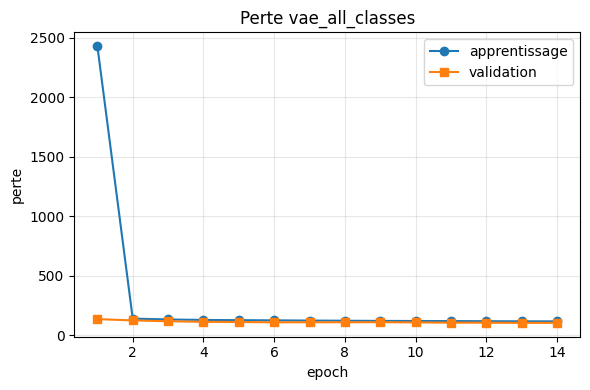

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score

from src.datasets import CLASSES, HEALTHY, TensorImageDataset, build_transform, get_split_tensors, make_loader
from src.metrics import anomaly_metrics, plot_roc
from src.models import VAE
from src.ood import fit_threshold
from src.train import fit_reconstruction, load_best, reconstruction_scores, record_experiment
from src.utils import load_json, save_json

P5 = cfg["part5"]
SIZE = cfg["resolution"]["ae"]
OUT = paths["results"] / "05_vae"
OUT.mkdir(parents=True, exist_ok=True)
BS, NW = cfg["train"]["batch_size"], cfg["data"]["num_workers"]
H_IDX = CLASSES.index(HEALTHY)

data = get_split_tensors(paths, DATA_ROOT, SIZE)
tf_train, tf_eval = build_transform(True, augment="flip"), build_transform(False)

def ds(split, healthy_only=False, train=False):
    df, x = data[split]
    mask = (df["label"] == H_IDX).to_numpy() if healthy_only else np.ones(len(df), bool)
    return df[mask].reset_index(drop=True), TensorImageDataset(x[torch.tensor(mask)], df["label"][mask], tf_train if train else tf_eval)

def train_vae(tag, healthy_only):
    set_seed(cfg["seed"])
    m = VAE(P5["latent_dim"])
    hp = {"latent_dim": P5["latent_dim"], "beta": P5["beta"], "epochs": P5["epochs"], "lr": P5["lr"], "img_size": SIZE,
          "train_data": "saines uniquement" if healthy_only else "toutes les classes", "loss": "SSE + beta*KL (-ELBO)"}
    _, d_tr = ds("train", healthy_only, train=True)
    _, d_va = ds("val", healthy_only)
    exp = OUT / tag
    fit_reconstruction(m, make_loader(d_tr, BS, True, NW, cfg["seed"]), make_loader(d_va, 256, False, NW), exp,
                       P5["epochs"], P5["lr"], kind="vae", beta=P5["beta"], max_minutes=cfg["train"]["max_minutes"],
                       resume=cfg["train"]["resume"], hparams=hp)
    m = load_best(m, exp)
    _ = record_experiment(paths["results"], f"P5_{tag}", "5", m, exp, SIZE, hparams=hp)
    return m

vae_all = train_vae("vae_all_classes", healthy_only=False)

## 1. Espace latent : projection 2D de μ(x), colorée par classe
#
# On projette les moyennes latentes μ(x) d'un échantillon de validation avec **t-SNE** (préserve les voisinages locaux ; les distances entre amas éloignés ne sont pas interprétables) et, si disponible, **UMAP** (préserve mieux la structure globale).
#
# Le VAE n'a **jamais vu les étiquettes** : si des amas par classe apparaissent, c'est que les maladies modifient fortement l'apparence globale (couleur, texture). Un recouvrement indique que le latent encode surtout autre chose (forme, orientation, éclairage, fond).

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


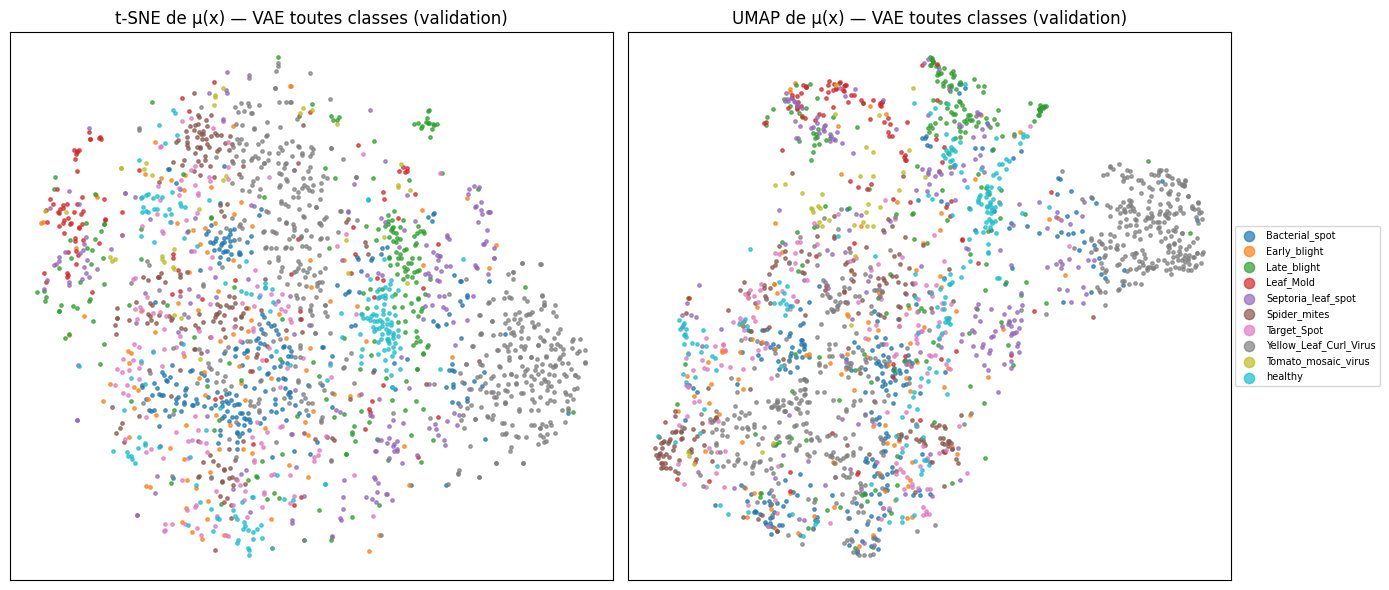

In [3]:
df_val, d_val = ds("val")
rng = np.random.default_rng(cfg["seed"])
idx = rng.choice(len(d_val), min(P5["tsne_points"], len(d_val)), replace=False)
with torch.no_grad():
    mu = torch.cat([vae_all.encode(torch.stack([d_val[i][0] for i in idx[s:s + 256]]).to(DEVICE))[0].cpu()
                    for s in range(0, len(idx), 256)]).numpy()
labels = df_val.loc[idx, "class_name"].to_numpy()

proj = {"t-SNE": TSNE(2, perplexity=min(30, len(idx) // 4), random_state=cfg["seed"], init="pca").fit_transform(mu)}
try:
    import umap
    proj["UMAP"] = umap.UMAP(random_state=cfg["seed"]).fit_transform(mu)
except ImportError:
    print("umap-learn non installé : seule la projection t-SNE est affichée.")

fig, axes = plt.subplots(1, len(proj), figsize=(7 * len(proj), 6), squeeze=False)
colors = plt.cm.tab10(np.linspace(0, 1, len(CLASSES)))
for ax, (name, p) in zip(axes[0], proj.items()):
    for c, col in zip(CLASSES, colors):
        sel = labels == c
        ax.scatter(p[sel, 0], p[sel, 1], s=6, color=col, label=c, alpha=0.7)
    ax.set(title=f"{name} de μ(x) — VAE toutes classes (validation)", xticks=[], yticks=[])
axes[0, -1].legend(markerscale=3, fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
fig.savefig(OUT / "latent_projection.png", dpi=150)

 ## 2. Interpolations entre deux feuilles
#
# On décode $z_t = (1-t)\,\mu(x_A) + t\,\mu(x_B)$ pour $t \in [0, 1]$. Dans un VAE, le chemin reste dans une zone dense du latent (grâce au KL) : les images intermédiaires sont des feuilles plausibles, contrairement à un AE classique où l'entre-deux peut ne correspondre à rien.

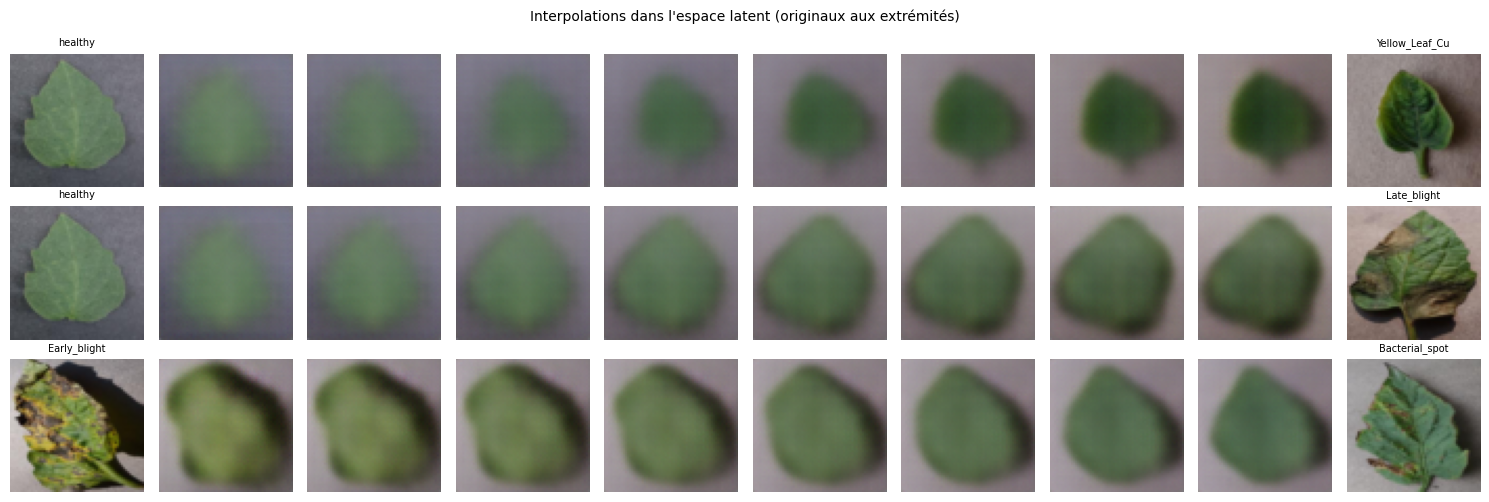

In [4]:
@torch.no_grad()
def interpolate(i_a, i_b, steps=8):
    xa, xb = d_val[i_a][0][None].to(DEVICE), d_val[i_b][0][None].to(DEVICE)
    za, zb = vae_all.encode(xa)[0], vae_all.encode(xb)[0]
    ts = torch.linspace(0, 1, steps, device=DEVICE)[:, None]
    return torch.cat([xa, vae_all.decode((1 - ts) * za + ts * zb), xb]).cpu()

pairs = [(HEALTHY, "Yellow_Leaf_Curl_Virus"), (HEALTHY, "Late_blight"), ("Early_blight", "Bacterial_spot")]
fig, axes = plt.subplots(len(pairs), 10, figsize=(15, 1.7 * len(pairs)))
for r, (a, b) in enumerate(pairs):
    ia = df_val.index[df_val["class_name"] == a][0]
    ib = df_val.index[df_val["class_name"] == b][0]
    for c, im in enumerate(interpolate(ia, ib)):
        axes[r, c].imshow(im.permute(1, 2, 0).clamp(0, 1))
        axes[r, c].axis("off")
    axes[r, 0].set_title(a[:14], fontsize=7)
    axes[r, -1].set_title(b[:14], fontsize=7)
fig.suptitle("Interpolations dans l'espace latent (originaux aux extrémités)", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "interpolations.png", dpi=130)

## 3. Génération par échantillonnage $z \sim \mathcal N(0, I)$

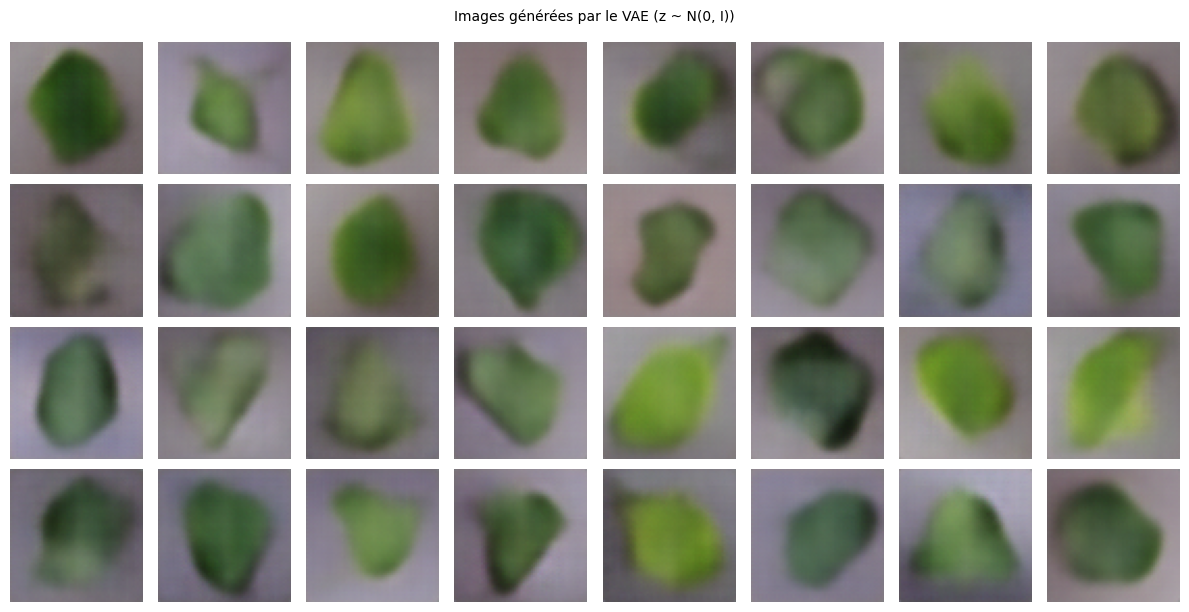

In [5]:
with torch.no_grad():
    torch.manual_seed(cfg["seed"])
    gen = vae_all.decode(torch.randn(32, P5["latent_dim"], device=DEVICE)).cpu()
fig, axes = plt.subplots(4, 8, figsize=(12, 6.2))
for a, im in zip(axes.ravel(), gen):
    a.imshow(im.permute(1, 2, 0).clamp(0, 1))
    a.axis("off")
fig.suptitle("Images générées par le VAE (z ~ N(0, I))", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "samples.png", dpi=130)

**À commenter** : les images générées sont **floues** — limite classique du VAE (décodeur gaussien + perte quadratique = moyenne des reconstructions possibles ; compromis reconstruction/KL). Elles reproduisent la forme et la couleur globales, rarement des lésions nettes. Comparer avec ce qu'apporterait un GAN (images nettes, mais pas d'encodeur ni de vraisemblance, entraînement instable).
#
## 4. −ELBO vs erreur de l'AE comme score d'anomalie
#
# Protocole identique à la partie 3 : VAE entraîné **sur les feuilles saines uniquement** ; scores calculés sur la validation (choix et seuil), puis **une seule** évaluation sur le test. Trois scores VAE (avec $z = \mu$, sans tirage aléatoire, pour un score déterministe) :
# - `rec` : erreur de reconstruction seule ;
# - `kl` : distance du code à la loi a priori (l'image « tombe »-t-elle dans une zone habituelle du latent ?) ;
# - `neg_elbo` = rec + KL : borne supérieure de $-\log p(x)$, score probabiliste « naturel ».

[vae_healthy] epoch  1/30 | loss 282.98034 / val 239.64764 | 15s
[vae_healthy] epoch  2/30 | loss 171.56088 / val 171.78339 | 11s
[vae_healthy] epoch  3/30 | loss 157.03217 / val 155.01918 | 12s
[vae_healthy] epoch  4/30 | loss 148.14327 / val 138.51616 | 12s
[vae_healthy] epoch  5/30 | loss 141.44439 / val 134.47066 | 12s
[vae_healthy] epoch  6/30 | loss 135.90744 / val 130.32445 | 12s
[vae_healthy] epoch  7/30 | loss 132.63952 / val 126.93076 | 11s
[vae_healthy] epoch  8/30 | loss 129.65450 / val 121.15512 | 14s
[vae_healthy] epoch  9/30 | loss 126.93004 / val 117.20845 | 12s
[vae_healthy] epoch 10/30 | loss 124.39749 / val 113.50706 | 13s
[vae_healthy] epoch 11/30 | loss 123.25847 / val 112.94345 | 13s
[vae_healthy] epoch 12/30 | loss 121.18688 / val 110.05671 | 12s
[vae_healthy] epoch 13/30 | loss 119.79482 / val 110.01216 | 12s
[vae_healthy] epoch 14/30 | loss 118.77906 / val 106.70293 | 12s
[vae_healthy] epoch 15/30 | loss 116.97473 / val 103.50334 | 13s
[vae_healthy] epoch 16/30

/content/drive/MyDrive/diagnoculture/src/utils.py:268: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)


AUROC sain/malade sur la VALIDATION : {'rec': np.float64(0.6476), 'kl': np.float64(0.8068), 'neg_elbo': np.float64(0.6732)}


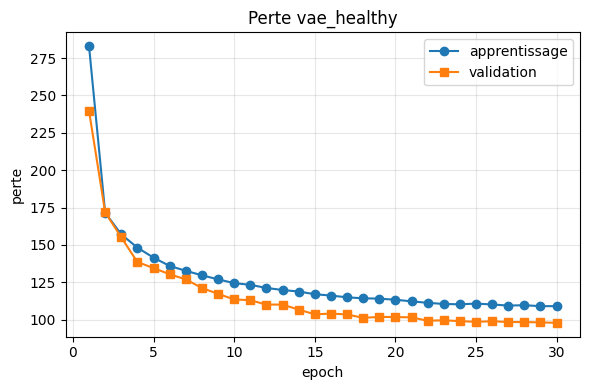

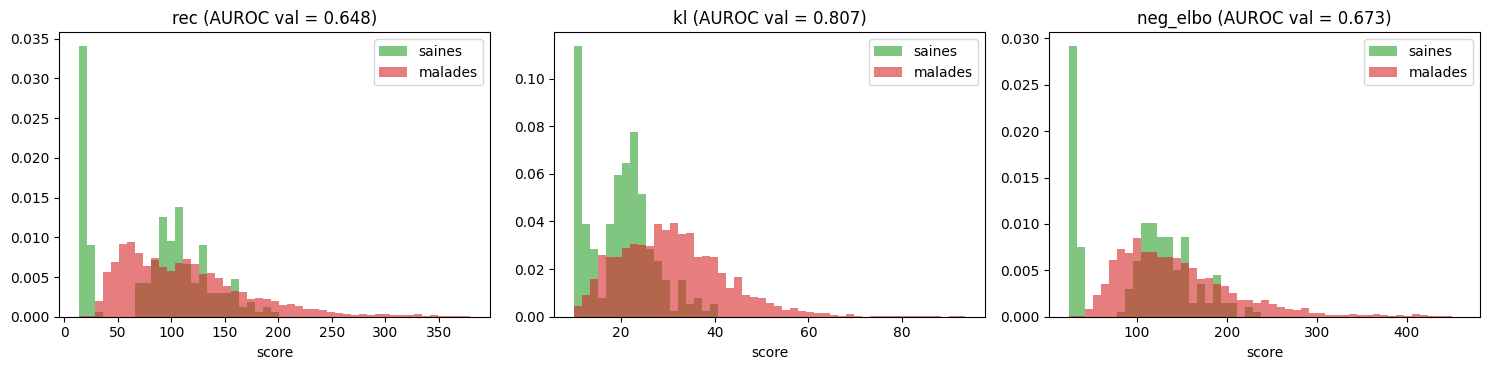

In [6]:
vae_h = train_vae("vae_healthy", healthy_only=True)
s_val = reconstruction_scores(vae_h, make_loader(d_val, 256, False, NW), kind="vae")
is_h_val = (df_val["label"] == H_IDX).to_numpy()
val_auc = {k: roc_auc_score(~is_h_val, v) for k, v in s_val.items()}
ae_info = load_json(paths["results"] / "03_autoencoders" / "best_ae.json")
print("AUROC sain/malade sur la VALIDATION :", {k: round(v, 4) for k, v in val_auc.items()})

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, k in zip(axes, ["rec", "kl", "neg_elbo"]):
    bins = np.linspace(np.percentile(s_val[k], 0.5), np.percentile(s_val[k], 99.5), 50)
    ax.hist(s_val[k][is_h_val], bins, alpha=0.6, density=True, color="tab:green", label="saines")
    ax.hist(s_val[k][~is_h_val], bins, alpha=0.6, density=True, color="tab:red", label="malades")
    ax.set(title=f"{k} (AUROC val = {val_auc[k]:.3f})", xlabel="score")
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "vae_scores_val.png", dpi=150)

,score,auroc,recall_anomalies,false_alarm_rate
0,AE (ae_k16_denoise) — erreur MSE,0.6371,0.1821,0.0377
1,VAE-sain — −ELBO,0.6565,0.2107,0.0293


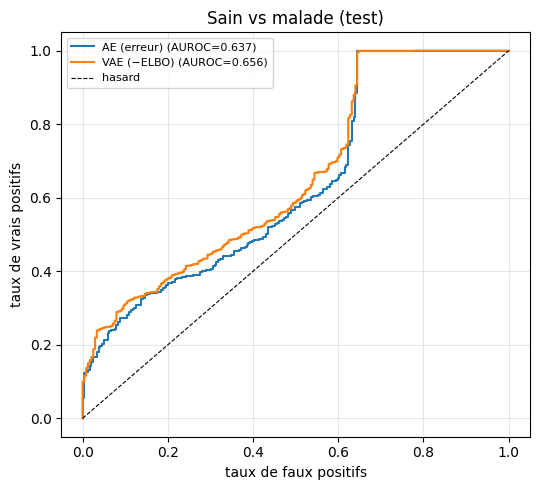

In [7]:
# ===== ÉVALUATION UNIQUE SUR LE TEST du VAE-sain (score −ELBO, fixé a priori) =====
guard.register("P5_vae_healthy_neg_elbo", force=FORCE_TEST_RERUN)
df_test, d_test = ds("test")
is_h_test = (df_test["label"] == H_IDX).to_numpy()
tau = fit_threshold(s_val["neg_elbo"][is_h_val], 1 - cfg["part3"]["threshold_percentile"] / 100, split_name="val")
s_test = reconstruction_scores(vae_h, make_loader(d_test, 256, False, NW), kind="vae")["neg_elbo"]
vae_m = anomaly_metrics(s_test[is_h_test], s_test[~is_h_test], tau)
ae_m = load_json(paths["results"] / "03_autoencoders" / "test_metrics.json")     # AE : résultats du nb 03, sans ré-évaluation
ae_scores = pd.read_csv(paths["results"] / "03_autoencoders" / "test_scores.csv")
cmp = pd.DataFrame([{"score": f"AE ({ae_info['tag']}) — erreur MSE", **{k: ae_m[k] for k in ("auroc", "recall_anomalies", "false_alarm_rate")}},
                    {"score": "VAE-sain — −ELBO", **{k: vae_m[k] for k in ("auroc", "recall_anomalies", "false_alarm_rate")}}]).round(4)
cmp.to_csv(OUT / "ae_vs_vae_test.csv", index=False)
save_json({"val_auroc": val_auc, "test": vae_m}, OUT / "vae_anomaly_metrics.json")
ah = (ae_scores["class_name"] == HEALTHY).to_numpy()
plot_roc({"AE (erreur)": (ae_scores["score"][ah], ae_scores["score"][~ah]),
          "VAE (−ELBO)": (s_test[is_h_test], s_test[~is_h_test])}, OUT / "roc_ae_vs_vae.png", "Sain vs malade (test)")
cmp

## À rédiger
# - **Latent** : séparation des classes sans supervision ? Quelles maladies se mélangent (cohérent avec les confusions du classifieur ?).
# - **Interpolations / génération** : plausibilité, flou, diversité. Utilité éventuelle comme augmentation de données (probablement limitée : images floues, peu de lésions fines).
# - **−ELBO vs erreur AE** : le terme KL apporte-t-il une information complémentaire (AUROC de `kl` seul) ? Le VAE, plus régularisé, reconstruit moins bien en général : est-ce un avantage (anomalies moins bien reconstruites) ou un inconvénient (feuilles saines aussi mal reconstruites) ? Lien avec la question de synthèse n°4.bold text